# Train Peng and Segerstolpe, test Baron

This workflow uses the auto_annot tools from besca to newly annotate a scRNAseq dataset based on one or more preannotated datasets. Ideally, these datasets come from a similar tissue and condition.

We use supervised machine learning methods to annotate each individual cell utilizing methods like support vector machines (SVM) or logistic regression.

First, the traning dataset(s) and the testing dataset are loaded from h5ad files or made available as adata objects. Next, the training and testing datasets are corrected using scanorama, and the training datasets are then merged into one anndata object. Then, the classifier is trained utilizing the merged training data. Finally, the classifier is applied to the testing dataset to predict the cell types. If the testing dataset is already annotated (to test the algorithm), a report including confusion matrices can be generated.

In [57]:
import besca as bc

In [58]:
import scanpy as sc
import scvelo as scv

### test load datasets with scvelo

Apparently the scv loader makes sure the adata objects are all in comparable format whereas the sc loader loads them as is.

In [59]:
adata_test = sc.read('standard_workflow_besca2_0.annotated.h5ad') #GSM2230757 Baron

In [60]:
adata_test_orig  = sc.read('standard_workflow_besca2_0.annotated.h5ad')

In [61]:
adata_train1 = sc.read('StdWf1_PRJCA001063_CRC_besca2.annotated.h5ad') #Peng

In [62]:
adata_train2 = sc.read('standard_workflow_besca2_0_annotated.h5ad') #Segerstolpe

Concatenation does not lead to errors when the scv loader is used.

In [63]:
train001 = adata_train1.concatenate(adata_train2)

In [64]:
adata_train_list = [adata_train1, adata_train2]

## Parameter specification

Give your analysis a name.

In [65]:
analysis_name = 'auto_annot_pubimage_panc1' # The analysis name will be used to name the output files

Specify column name of celltype annotation you want to train on.

In [66]:
celltype ='dblabel' # This needs to be a column in the .obs of the training datasets (and test dataset if you want to generate a report)

Choose a method:

- linear: Support Vector Machine with Linear Kernel
- sgd: Support Vector Machine with Linear Kernel using Stochastic Gradient Descent
- rbf: Support Vector Machine with radial basis function kernel. Very time intensive, use only on small datasets.
- logistic_regression: Standard logistic classifier iwth multinomial loss.
- logistic_regression_ovr: Logistic Regression with one versus rest classification.
- logistic_regression_elastic: Logistic Regression with elastic loss, cross validates among multiple l1 ratios.

In [67]:
method = 'logistic_regression'

Specify merge method. Needs to be either scanorama or naive.

In [68]:
merge = 'scanorama' # We recommend to use scanorama here

Decide if you want to use the raw format or highly variable genes. Raw increases computational time and does not necessarily improve predictions.

In [69]:
use_raw = False # We recommend to use False here

You can choose to only consider a subset of genes from a signature set or use all genes.

In [70]:
genes_to_use = 'all' # We suggest to use all here, but the runtime is strongly improved if you select an appropriate gene set

Column names need to be standardised so the function knows which columns to compare.

In [71]:
#adata_test.obs["dblabel"] = adata_test.obs.celltype3_original
#adata_test_orig.obs["dblabel"] = adata_test_orig.obs.celltype3_original

#adata_train_list[1].obs["dblabel"] = adata_train_list[1].obs.celltype3

In [72]:
adata_test.obs

,Individual,assigned_cluster,barcode,percent_mito,n_counts,n_genes,leiden,celltype0,celltype1,celltype2,celltype3,dblabel
human1_lib1.final_cell_0001-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,GATGACGGAC-GGTGGGAT,0.0,22381.0,3526,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell
human1_lib1.final_cell_0002-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,GAGCGTTGCT-ACCTTCTT,0.0,27946.0,4201,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell
human1_lib1.final_cell_0003-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,CTTACGGG-CCATTACT,0.0,16889.0,2119,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell
human1_lib1.final_cell_0004-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,GATGTACACG-TTAAACTG,0.0,19295.0,2956,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell
human1_lib1.final_cell_0005-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,GAGATTGCGA-GTCGTCGT,0.0,15063.0,2715,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell,pancreatic acinar cell
...,...,...,...,...,...,...,...,...,...,...,...,...
human4_lib3.final_cell_0697-GSM2230760_human4_umifm_counts,GSM2230760_human4_umifm_counts,activated_stellate,GAGATCTCGG-GTCTCTCT,0.0,2095.0,1055,16,fibroblast,fibroblast,fibroblast,fibroblast,fibroblast
human4_lib3.final_cell_0698-GSM2230760_human4_umifm_counts,GSM2230760_human4_umifm_counts,alpha,GCTTACCT-ATGTTGGC,0.0,2022.0,1007,6,epithelial cell,enteroendocrine cell,pancreatic A cell,pancreatic A cell,pancreatic A cell
human4_lib3.final_cell_0699-GSM2230760_human4_umifm_counts,GSM2230760_human4_umifm_counts,beta,TGACACAGTTT-TTGTCGCC,0.0,2197.0,942,7,epithelial cell,enteroendocrine cell,type B pancreatic cell,type B pancreatic cell,type B pancreatic cell
human4_lib3.final_cell_0700-GSM2230760_human4_umifm_counts,GSM2230760_human4_umifm_counts,beta,GACGACTCCT-CGCTAATA,0.0,2151.0,1031,7,epithelial cell,enteroendocrine cell,type B pancreatic cell,type B pancreatic cell,type B pancreatic cell


In [73]:
adata_train_list[0].obs.dblabel.unique()

[fibroblast, pancreatic stellate cell, CD1c-positive myeloid dendritic cell, macrophage, blood vessel endothelial cell, ..., regulatory T cell, pancreatic acinar cell, proliferating B cell, neural cell, pancreatic epsilon cell]
Length: 17
Categories (17, object): [fibroblast, pancreatic stellate cell, CD1c-positive myeloid dendritic cell, macrophage, ..., pancreatic acinar cell, proliferating B cell, neural cell, pancreatic epsilon cell]

In [74]:
adata_train_list[1].obs.dblabel.unique()

[pancreatic A cell, PP cell, enteroendocrine cell, pancreatic ductal cell, type B pancreatic cell, pancreatic D cell, pancreatic acinar cell, fibroblast, blood vessel endothelial cell, macrophage]
Categories (10, object): [pancreatic A cell, PP cell, enteroendocrine cell, pancreatic ductal cell, ..., pancreatic acinar cell, fibroblast, blood vessel endothelial cell, macrophage]

In [75]:
adata_test.var.dtypes

ENSEMBL         category
SYMBOL          category
n_cells            int64
total_counts     float32
frac_reads       float32
dtype: object

In [76]:
adata_train_list[0].var.dtypes

ENSEMBL           object
SYMBOL          category
n_cells            int64
total_counts     float32
frac_reads       float32
dtype: object

In [77]:
#solves type issues in naive merge
del adata_train_list[0].raw
del adata_train_list[1].raw
del adata_test.raw

## Correct datasets (e.g. using scanorama) and merge training datasets

This function merges training datasets, removes unwanted genes, and if scanorama is used corrects for datasets.

In [78]:
adata_train, adata_test_corrected = bc.tl.auto_annot.merge_data(adata_train_list, adata_test, genes_to_use = genes_to_use, merge = merge)

merging with scanorama
using scanorama rn
Found 806 genes among all datasets
[[0.         0.4176045  0.1742327 ]
 [0.         0.         0.87660772]
 [0.         0.         0.        ]]
Processing datasets (1, 2)
Processing datasets (0, 1)
Processing datasets (0, 2)
integrating training set


## Train the classifier

The returned scaler is fitted on the training dataset (to zero mean and scaled to unit variance). The scaling will then be applied to the counts in the testing dataset and then the classifier is applied to the scaled testing dataset (see next step, adata_predict()). This function will run multiple jobs in parallel if if logistic regression was specified as method.

In [79]:
classifier, scaler = bc.tl.auto_annot.fit(adata_train, method, celltype, njobs=10)

[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done   5 out of   5 | elapsed:  9.6min finished


## Prediction

If in addition to the most likely class you would like to have all class probabilities returned use the following function. (This is only a sensible choice if using logistic regression.)

In [80]:
adata_predicted = bc.tl.auto_annot.adata_pred_prob(classifier = classifier, scaler = scaler, adata_pred = adata_test_corrected, adata_orig = adata_test_orig, threshold = 0.0)

## Output

The adata object that includes the predicted cell type annotation can be written out as h5ad file.

In [81]:
adata_predicted.write('./adata_predicted_panc1.h5ad')

... storing 'auto_annot' as categorical


If the testing dataset included already a cell type annotation, a report can be generated and written, which includes metrics,  confusion matrices and comparative umap plots.

In [82]:
adata_predicted.obs

,Individual,assigned_cluster,barcode,percent_mito,n_counts,n_genes,leiden,celltype0,celltype1,celltype2,...,pancreatic D cell,pancreatic acinar cell,pancreatic ductal cell,pancreatic epsilon cell,pancreatic stellate cell,plasma cell,proliferating B cell,"proliferating CD8-positive, alpha-beta T cell",regulatory T cell,type B pancreatic cell
human1_lib1.final_cell_0001-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,GATGACGGAC-GGTGGGAT,0.0,22381.0,3526,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,...,0.000332,0.860731,0.000510,6.456316e-05,0.001369,0.006704,0.005658,0.000355,0.000352,0.000633
human1_lib1.final_cell_0002-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,GAGCGTTGCT-ACCTTCTT,0.0,27946.0,4201,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,...,0.016985,0.000847,0.005521,1.573484e-02,0.009498,0.091644,0.031415,0.025108,0.001750,0.027757
human1_lib1.final_cell_0003-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,CTTACGGG-CCATTACT,0.0,16889.0,2119,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,...,0.000012,0.986771,0.000764,3.276903e-05,0.000466,0.002674,0.000045,0.000024,0.000031,0.000004
human1_lib1.final_cell_0004-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,GATGTACACG-TTAAACTG,0.0,19295.0,2956,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,...,0.000016,0.826907,0.058085,9.780948e-06,0.001141,0.080739,0.000655,0.001286,0.000040,0.001432
human1_lib1.final_cell_0005-GSM2230757_human1_umifm_counts,GSM2230757_human1_umifm_counts,acinar,GAGATTGCGA-GTCGTCGT,0.0,15063.0,2715,1,epithelial cell,pancreatic acinar cell,pancreatic acinar cell,...,0.000238,0.509579,0.147690,5.227234e-05,0.007040,0.077028,0.000364,0.001542,0.153566,0.000164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
human4_lib3.final_cell_0697-GSM2230760_human4_umifm_counts,GSM2230760_human4_umifm_counts,activated_stellate,GAGATCTCGG-GTCTCTCT,0.0,2095.0,1055,16,fibroblast,fibroblast,fibroblast,...,0.000017,0.000035,0.000042,4.491933e-05,0.019665,0.001258,0.000006,0.000022,0.000010,0.000008
human4_lib3.final_cell_0698-GSM2230760_human4_umifm_counts,GSM2230760_human4_umifm_counts,alpha,GCTTACCT-ATGTTGGC,0.0,2022.0,1007,6,epithelial cell,enteroendocrine cell,pancreatic A cell,...,0.000042,0.007456,0.002502,2.108876e-03,0.002295,0.074226,0.000021,0.068285,0.002655,0.000187
human4_lib3.final_cell_0699-GSM2230760_human4_umifm_counts,GSM2230760_human4_umifm_counts,beta,TGACACAGTTT-TTGTCGCC,0.0,2197.0,942,7,epithelial cell,enteroendocrine cell,type B pancreatic cell,...,0.000458,0.001798,0.013580,7.436592e-04,0.008545,0.604371,0.013861,0.000425,0.000085,0.151599
human4_lib3.final_cell_0700-GSM2230760_human4_umifm_counts,GSM2230760_human4_umifm_counts,beta,GACGACTCCT-CGCTAATA,0.0,2151.0,1031,7,epithelial cell,enteroendocrine cell,type B pancreatic cell,...,0.000002,0.000025,0.000011,4.659512e-07,0.000330,0.000587,0.000009,0.000001,0.000002,0.997955


leiden clustering performed with a resolution of 1


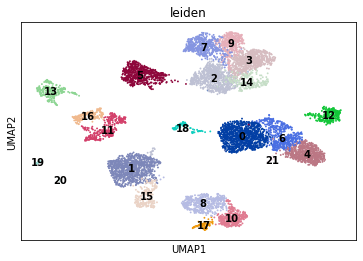

rank genes per cluster calculated using method wilcoxon.
mapping of cells to  leiden exported successfully to cell2labels.tsv
average.gct exported successfully to file
fract_pos.gct exported successfully to file
labelinfo.tsv successfully written out
./labelings/leiden/WilxRank.gct written out
./labelings/leiden/WilxRank.pvalues.gct written out
./labelings/leiden/WilxRank.logFC.gct written out


In [83]:
adata_predicted = bc.st.clustering(adata_predicted, '.')

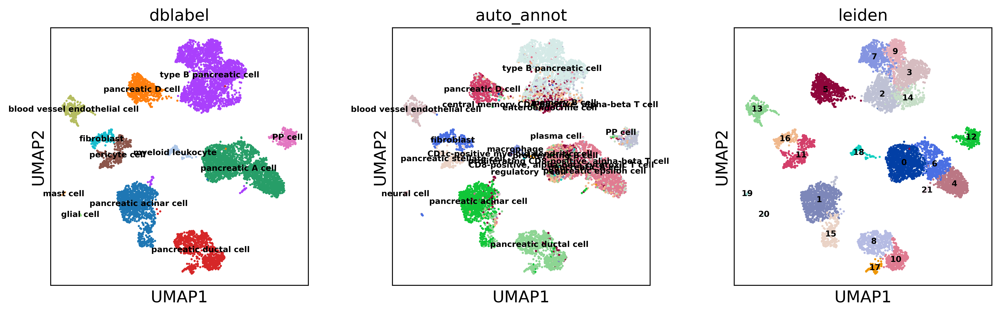

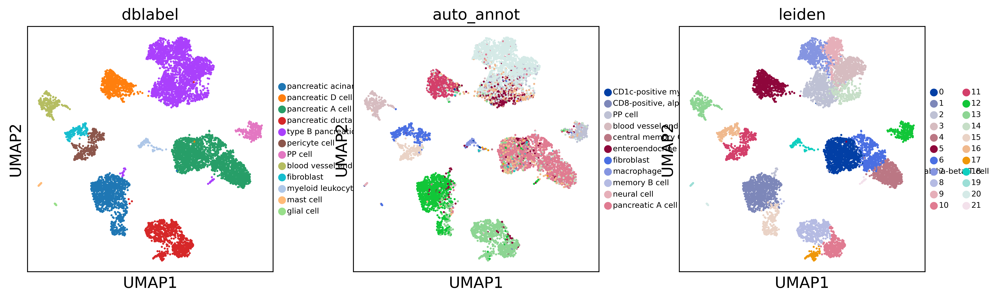

Confusion matrix, without normalization
Normalized confusion matrix


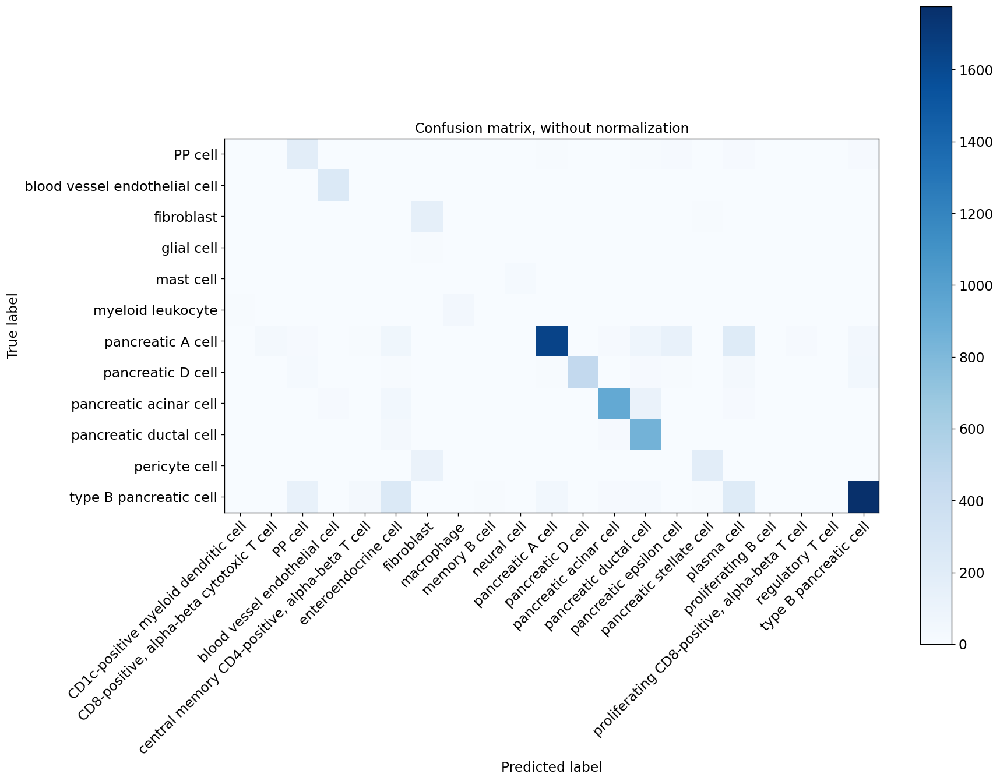

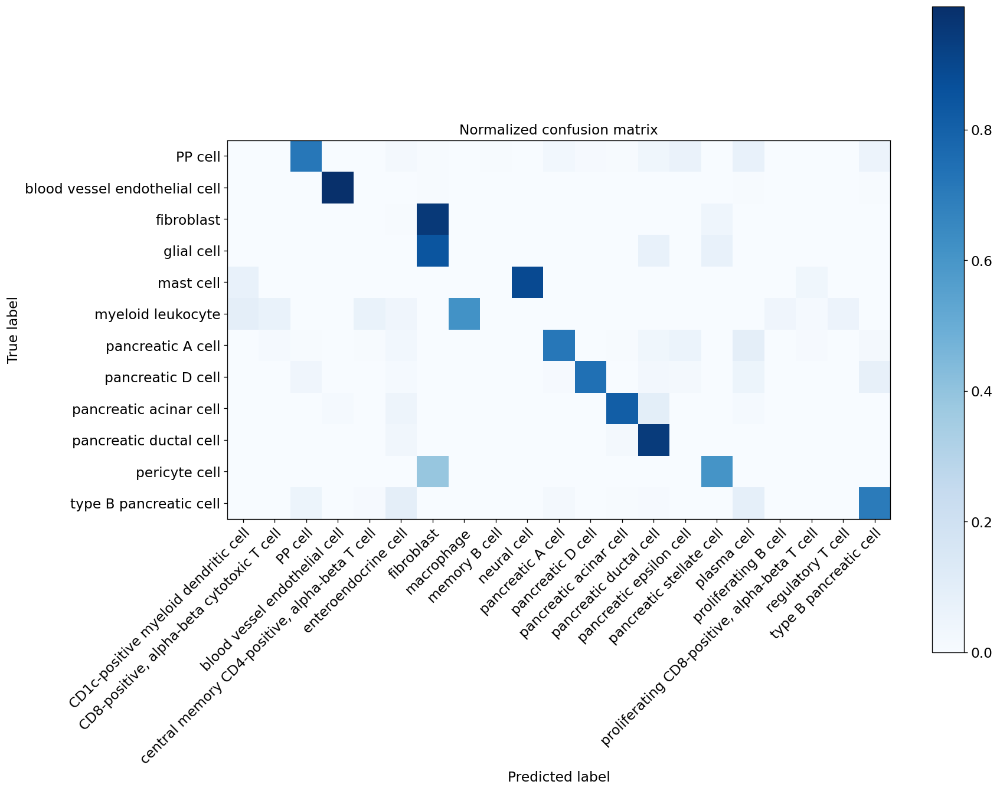

In [84]:
%matplotlib inline
sc.settings.set_figure_params(dpi=90)
bc.tl.auto_annot.report(adata_predicted, celltype, method, analysis_name, False, merge, use_raw, genes_to_use, clustering = 'leiden')

In [85]:
sc.settings.set_figure_params(dpi=240)

sc.pl.umap(adata_predicted, color=[celltype, 'auto_annot', 'leiden'], legend_loc='on data',legend_fontsize=7,  save= '.fig3_supp_panc1_ondata.svg')
sc.pl.umap(adata_predicted, color=[celltype, 'auto_annot', 'leiden'],legend_fontsize=7, wspace = 1.4, save = '.fig3_supp_panc1.svg')


In [86]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
from sklearn.metrics import confusion_matrix
def plot_confusion_matrix(y_true, y_pred, classes, celltype,
                          normalize=False,
                          title=None, numbers =False,
                          cmap=plt.cm.Blues, adata_predicted= None, asymmetric_matrix = True): 

    matplotlib.use('Agg')
    
    if not title:
        if normalize:
            title = 'Normalized confusion matrix'
        else:
            title = 'Confusion matrix, without normalization'

    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    # Only use the labels that appear in the data
    #classes = classes[unique_labels(y_true, y_pred)]
    if asymmetric_matrix == True:
        class_names =  np.unique(np.concatenate((adata_predicted.obs[celltype], adata_predicted.obs['auto_annot'])))
        class_names_orig = np.unique(adata_predicted.obs[celltype])
        class_names_pred = np.unique(adata_predicted.obs['auto_annot'])
        test_celltypes_ind = np.searchsorted(class_names, class_names_orig)
        train_celltypes_ind = np.searchsorted(class_names, class_names_pred)
        cm=cm[test_celltypes_ind,:][:,train_celltypes_ind]
    
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    fig, ax = plt.subplots(figsize=(15,15))
    im = ax.imshow(cm, interpolation='nearest', cmap=cmap)
    ax.figure.colorbar(im, ax=ax, shrink = 0.8)
    # We want to show all ticks...
    if asymmetric_matrix == True:
        ax.set(xticks=np.arange(cm.shape[1]),
               yticks=np.arange(cm.shape[0]),
               # ... and label them with the respective list entries
               xticklabels=class_names_pred, yticklabels=class_names_orig,
               title=title,
               ylabel='True label',
               xlabel='Predicted label')
    else:
        ax.set(xticks=np.arange(cm.shape[1]),
               yticks=np.arange(cm.shape[0]),
               # ... and label them with the respective list entries
               xticklabels=classes, yticklabels=classes,
               title=title,
               ylabel='True label',
               xlabel='Predicted label')
        
    ax.grid(False)
    #ax.tick_params(axis='both', which='major', labelsize=10)
    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
             rotation_mode="anchor")

    # Loop over data dimensions and create text annotations.
    if numbers == True:
        fmt = '.2f' if normalize else 'd'
        thresh = cm.max() / 2.
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, format(cm[i, j], fmt),
                        ha="center", va="center",
                        color="white" if cm[i, j] > thresh else "black")
    #fig.tight_layout()
    return ax

In [87]:
import os

Confusion matrix, without normalization
Normalized confusion matrix


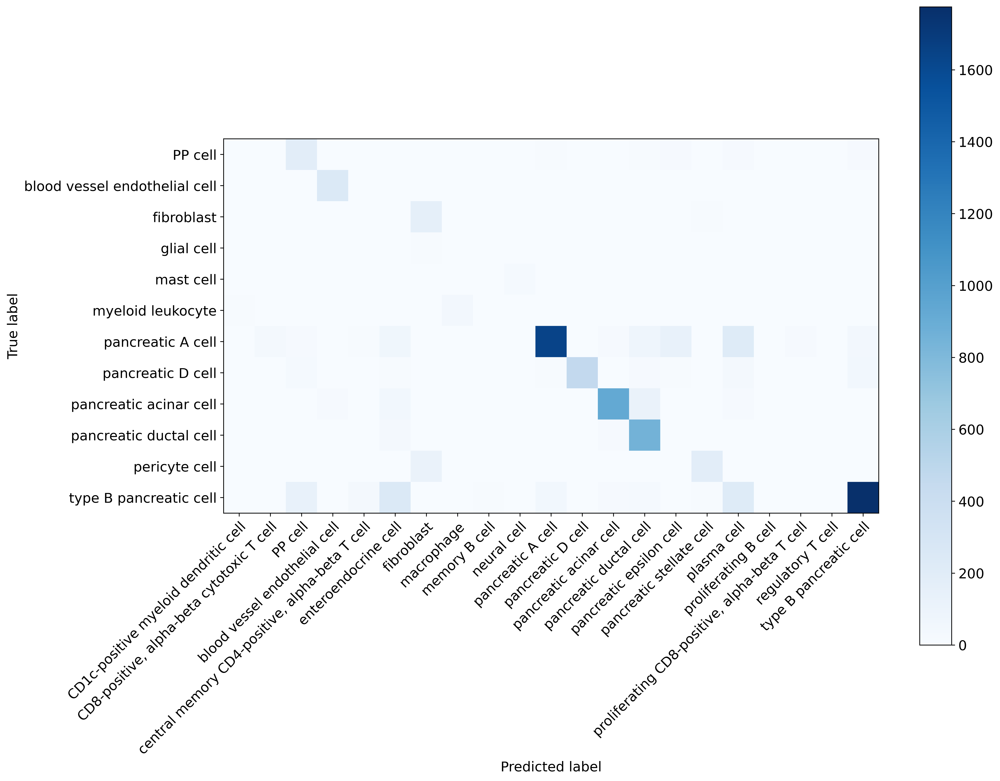

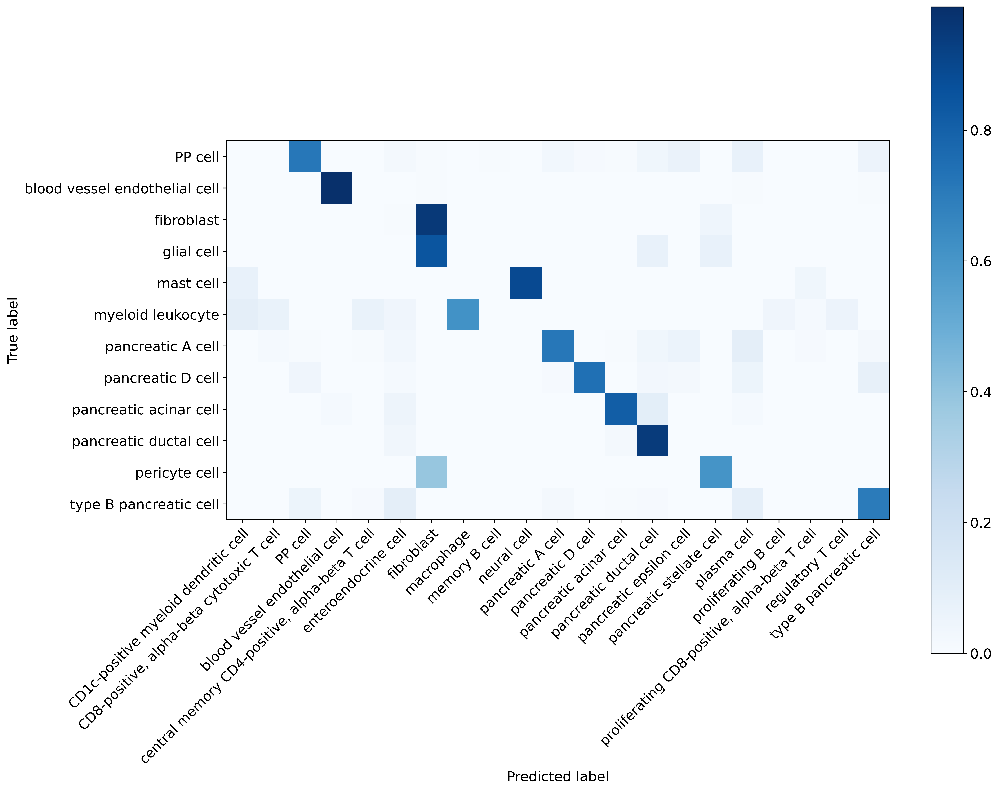

In [88]:
# make conf matrices (4)
class_names =  np.unique(np.concatenate((adata_predicted.obs[celltype], adata_predicted.obs['auto_annot'])))
np.set_printoptions(precision=2)
# Plot non-normalized confusion matrix
plot_confusion_matrix(adata_predicted.obs[celltype], adata_predicted.obs['auto_annot'], title = " ", classes=class_names, celltype=celltype ,numbers = False, adata_predicted = adata_predicted, asymmetric_matrix = True)
plt.savefig(os.path.join('fig3_supp_panc1_confusion_matrix_nonnormalised.svg'))

# Plot normalized confusion matrix with numbers
plot_confusion_matrix(adata_predicted.obs[celltype], adata_predicted.obs['auto_annot'], title = " ", classes=class_names,celltype=celltype,  normalize=True, numbers = False, adata_predicted = adata_predicted, asymmetric_matrix = True)
plt.savefig(os.path.join('fig3_supp_panc1_confusion_matrix_normalised.svg'))


# let's use a threshold

In [89]:
analysis_name = 'auto_annot_pubimage_threshold_panc1' # The analysis name will be used to name the output files

In [90]:
adata_predicted_threshold = bc.tl.auto_annot.adata_pred_prob(classifier = classifier, scaler = scaler, adata_pred = adata_test_corrected, adata_orig = adata_test_orig, threshold = 0.7)

In [91]:
adata_predicted_threshold.write('./adata_predicted_threshold_panc1.h5ad')

... storing 'auto_annot' as categorical


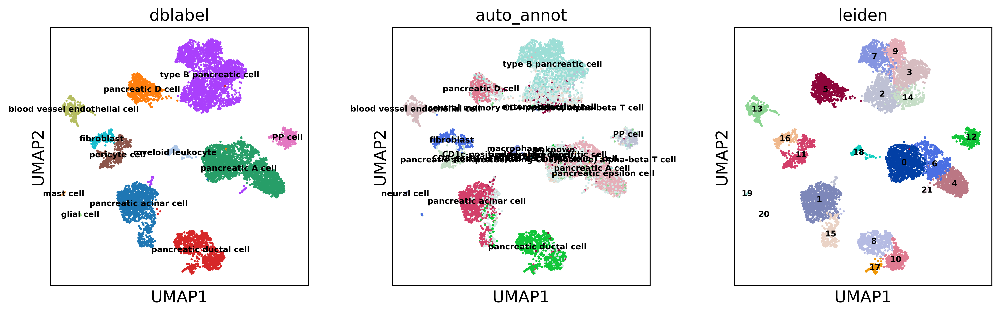

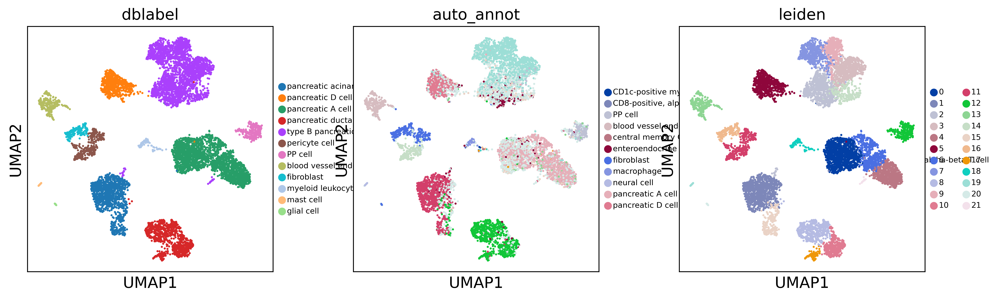

Confusion matrix, without normalization
Normalized confusion matrix


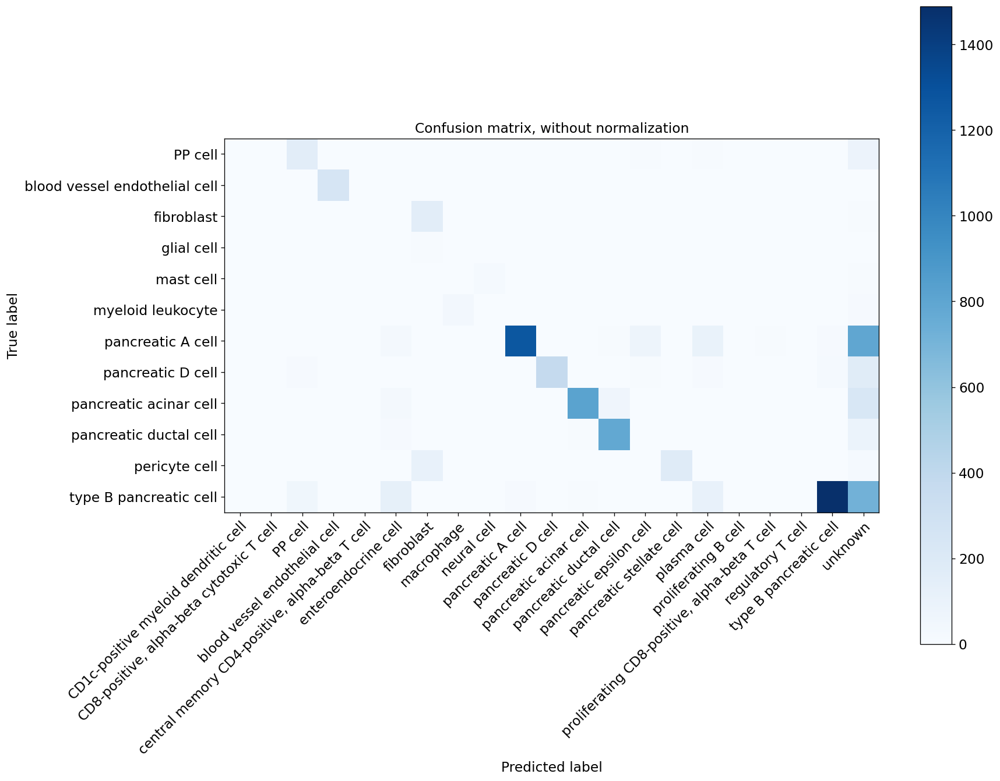

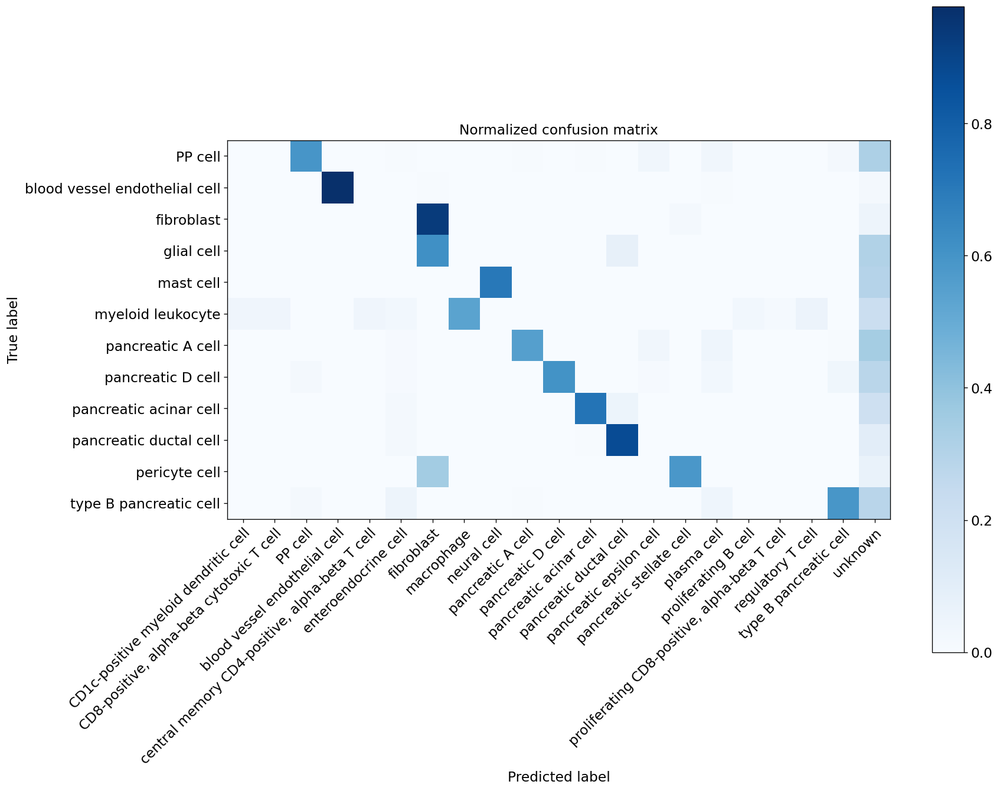

In [92]:
%matplotlib inline
sc.settings.set_figure_params(dpi=90)
bc.tl.auto_annot.report(adata_predicted_threshold, celltype, method, analysis_name, False, merge, use_raw, genes_to_use, clustering = 'leiden')

In [93]:
sc.settings.set_figure_params(dpi=240)

sc.pl.umap(adata_predicted_threshold, color=[celltype, 'auto_annot', 'leiden'], legend_loc='on data',legend_fontsize=7,  save= '.fig3_supp_panc1_threshold_ondata.svg')
sc.pl.umap(adata_predicted_threshold, color=[celltype, 'auto_annot', 'leiden'],legend_fontsize=7, wspace = 1.4, save = '.fig3_supp_panc1_threshold.svg')


Confusion matrix, without normalization
Normalized confusion matrix


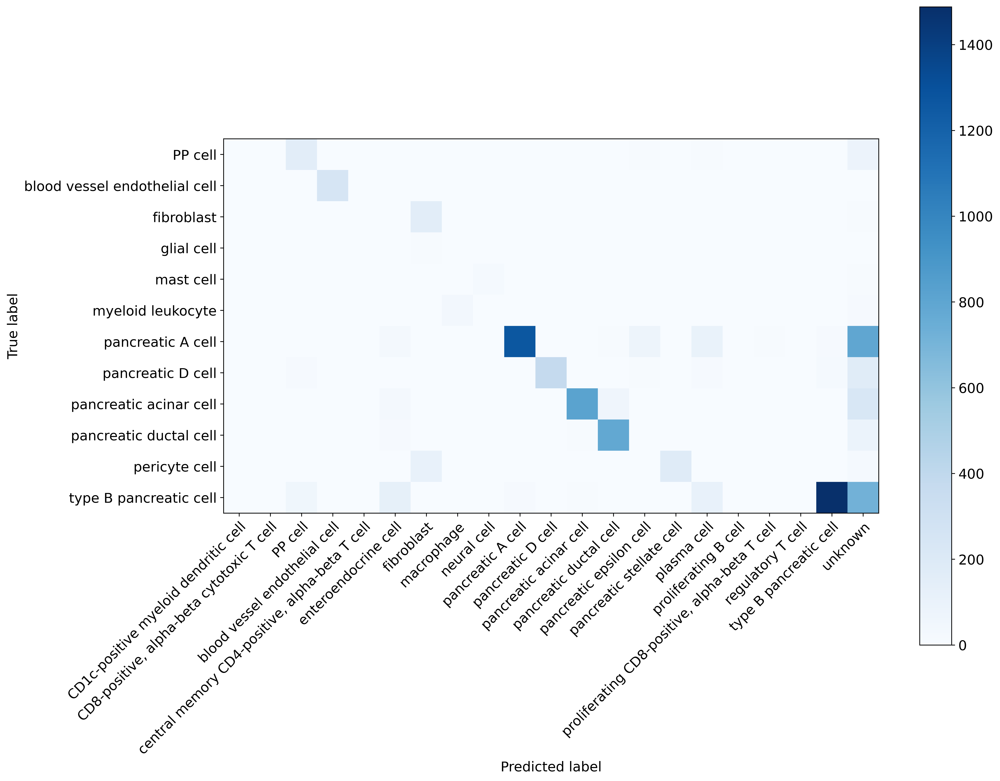

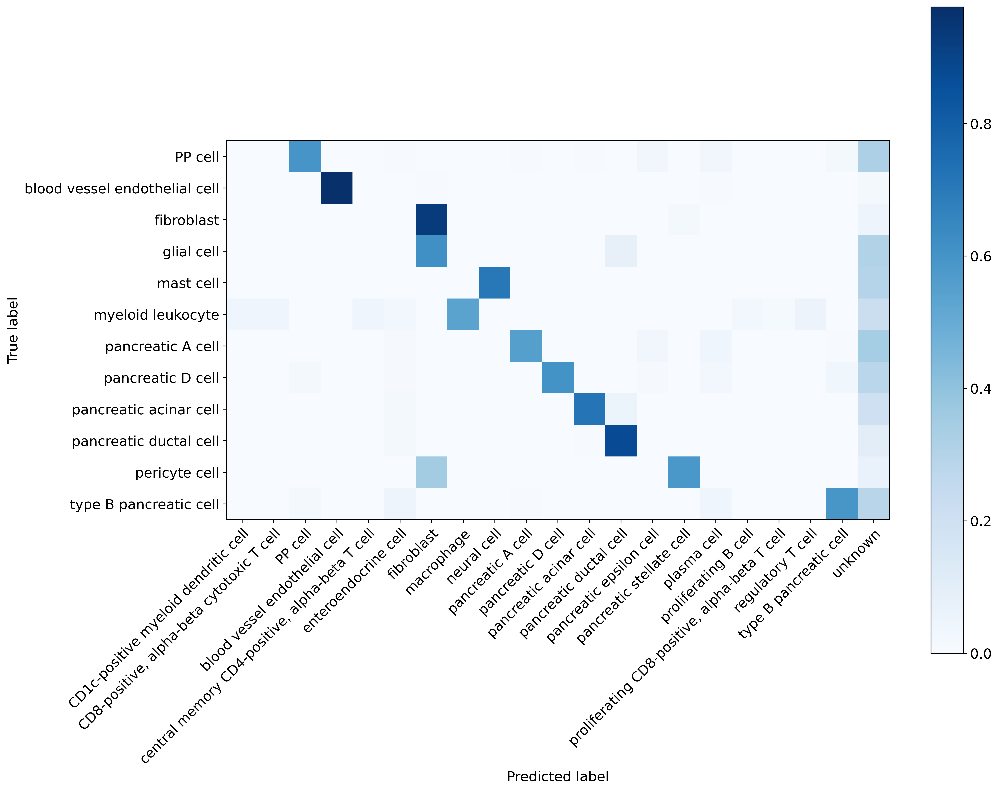

In [94]:
# make conf matrices (4)
class_names =  np.unique(np.concatenate((adata_predicted_threshold.obs[celltype], adata_predicted_threshold.obs['auto_annot'])))
np.set_printoptions(precision=2)
# Plot non-normalized confusion matrix
plot_confusion_matrix(adata_predicted_threshold.obs[celltype], adata_predicted_threshold.obs['auto_annot'], title = " ", classes=class_names, celltype=celltype ,numbers = False, adata_predicted = adata_predicted_threshold, asymmetric_matrix = True)
plt.savefig(os.path.join('fig3_supp_panc1_confusion_matrix_threshold_nonnormalised.svg'))

# Plot normalized confusion matrix with numbers
plot_confusion_matrix(adata_predicted_threshold.obs[celltype], adata_predicted_threshold.obs['auto_annot'], title = " ", classes=class_names,celltype=celltype,  normalize=True, numbers = False, adata_predicted = adata_predicted_threshold, asymmetric_matrix = True)
plt.savefig(os.path.join('fig3_supp_panc1_confusion_matrix_threshold_normalised.svg'))


# let's check if the differences in annotation make sense

In [93]:
 ## PROVIDED WITH BESCA
root_path = os.getcwd()

gmt_file_IMM= os.path.split(root_path)[0] + '/besca/besca/datasets/genesets/HumanCD45p_scseqCMs6.gmt'
bc.tl.sig.combined_signature_score(adata_predicted, gmt_file_IMM)


In [94]:
adata_predicted.var_names

Index(['ISG15', 'TNFRSF4', 'CPSF3L', 'MRPL20', 'ATAD3C', 'C1orf86', 'RER1',
       'TPRG1L', 'TNFRSF25', 'TNFRSF9',
       ...
       'DSCR3', 'BRWD1', 'BACE2', 'SIK1', 'C21orf33', 'ICOSLG', 'SUMO3',
       'SLC19A1', 'S100B', 'PRMT2'],
      dtype='object', length=1719)

In [99]:
scores = [x for x in adata_predicted.obs.columns if 'CD45' in x]
scores

['score_HumanCD45p_scseqCMs6_ActB_scanpy',
 'score_HumanCD45p_scseqCMs6_Activation_scanpy',
 'score_HumanCD45p_scseqCMs6_Basophil_scanpy',
 'score_HumanCD45p_scseqCMs6_Bcells_scanpy',
 'score_HumanCD45p_scseqCMs6_CCG1S_scanpy',
 'score_HumanCD45p_scseqCMs6_CCG2M_scanpy',
 'score_HumanCD45p_scseqCMs6_Cafs_scanpy',
 'score_HumanCD45p_scseqCMs6_Cellcycle_scanpy',
 'score_HumanCD45p_scseqCMs6_Checkpoint_scanpy',
 'score_HumanCD45p_scseqCMs6_Cyto_scanpy',
 'score_HumanCD45p_scseqCMs6_Cytotox_scanpy',
 'score_HumanCD45p_scseqCMs6_DCR_scanpy',
 'score_HumanCD45p_scseqCMs6_DCrec_scanpy',
 'score_HumanCD45p_scseqCMs6_DCs_scanpy',
 'score_HumanCD45p_scseqCMs6_Eff_scanpy',
 'score_HumanCD45p_scseqCMs6_Endo_scanpy',
 'score_HumanCD45p_scseqCMs6_Endot_scanpy',
 'score_HumanCD45p_scseqCMs6_Endothelial_scanpy',
 'score_HumanCD45p_scseqCMs6_Eosinophil_scanpy',
 'score_HumanCD45p_scseqCMs6_Epith_scanpy',
 'score_HumanCD45p_scseqCMs6_ExhB_scanpy',
 'score_HumanCD45p_scseqCMs6_Granulo_scanpy',
 'score_Hu

Indeed it seems like the classification of B cells is an improvement, whereas the varieties of T cells pose difficulties.

In [114]:
sc.pl.umap(adata_predicted, color= ["score_HumanCD45p_scseqCMs6_MemB_scanpy", "score_HumanCD45p_scseqCMs6_NaiveB_scanpy","CD4", "CD8A"], ncols = 2, wspace = 0.4, color_map = 'viridis',save= '.fig3_markers.svg')

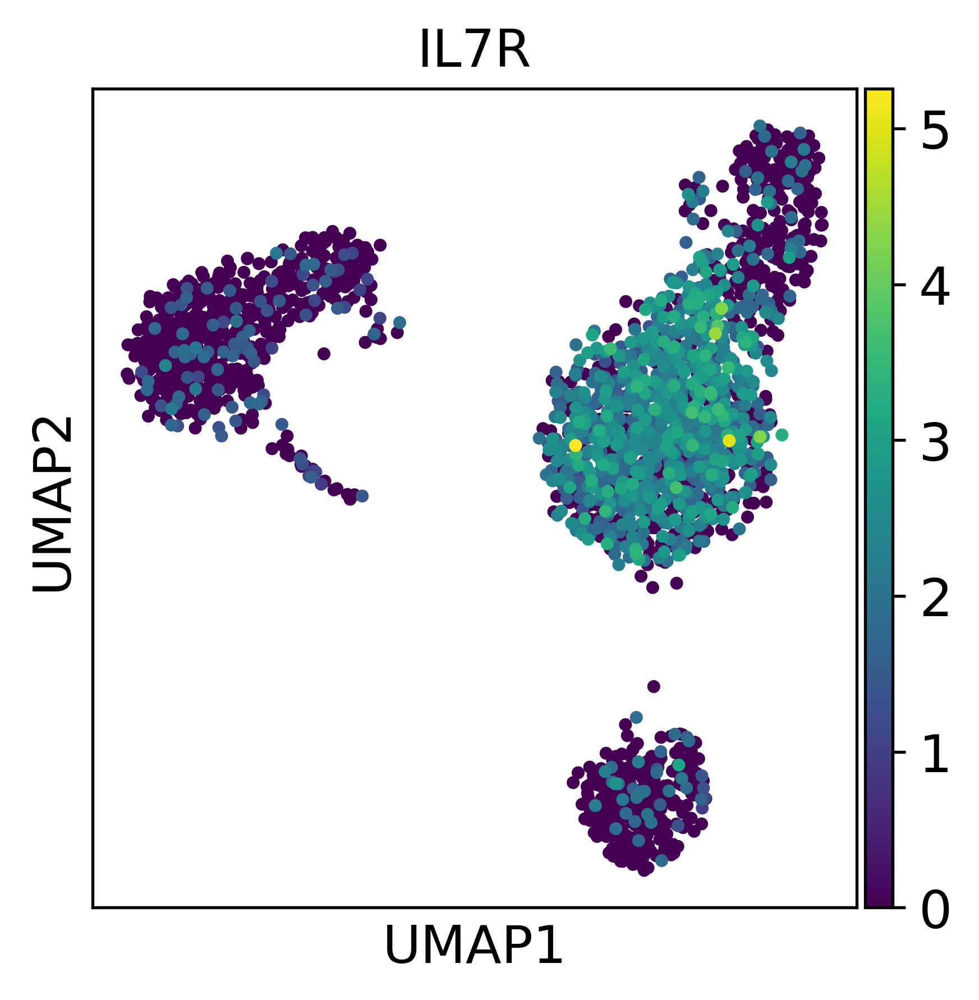

In [115]:
sc.pl.umap(adata_predicted, color= ["IL7R"], ncols = 2, wspace = 0.4, color_map = 'viridis')